In [1]:
import numpy as np
import matplotlib.pyplot as plt

<h2> Part a: </h2>

We consider the initial value problem

$$ \dot{x}(t)=-\lambda x(t), \qquad x(0)=1, $$

on the interval $$ t\in[0,1]\, where \lambda>0. $$

The exact solution is

$$ x(t)=e^{-\lambda t}. $$

The general Explicit Euler method for an ODE \(x'(t)=f(t,x(t))\) is given by

$$ x_{n+1}=x_n+h f(t_n,x_n), $$

where \(h\) is the step size and \(t_n=nh\).

For the given problem, \(f(t,x)=-lambda x\). Therefore, the Euler update formula becomes

$$ \boxed{x_{n+1}=(1-\lambda h)x_n}. $$

We implement this method in Python and compare the numerical solution with the exact solution for different values of \(lambda) and \(h\).

In [2]:
def explicit_euler(lam, h, x0=1.0, T=1.0):
    """
    Solve x'(t) = -lam * x(t), x(0) = x0,
    using the Explicit Euler method on [0, T].
    """
    N = int(round(T / h))
    h = T / N

    t = np.linspace(0, T, N + 1)
    x = np.zeros(N + 1)

    x[0] = x0

    for n in range(N):
        x[n + 1] = x[n] - h * lam * x[n]

    return t, x

We compare the numerical and exact solutions for several values of lambda.

We use three step sizes:

$$ h=0.1, h=0.02, h=0.005. $$

This allows us to observe how the numerical solution changes as the step size decreases.

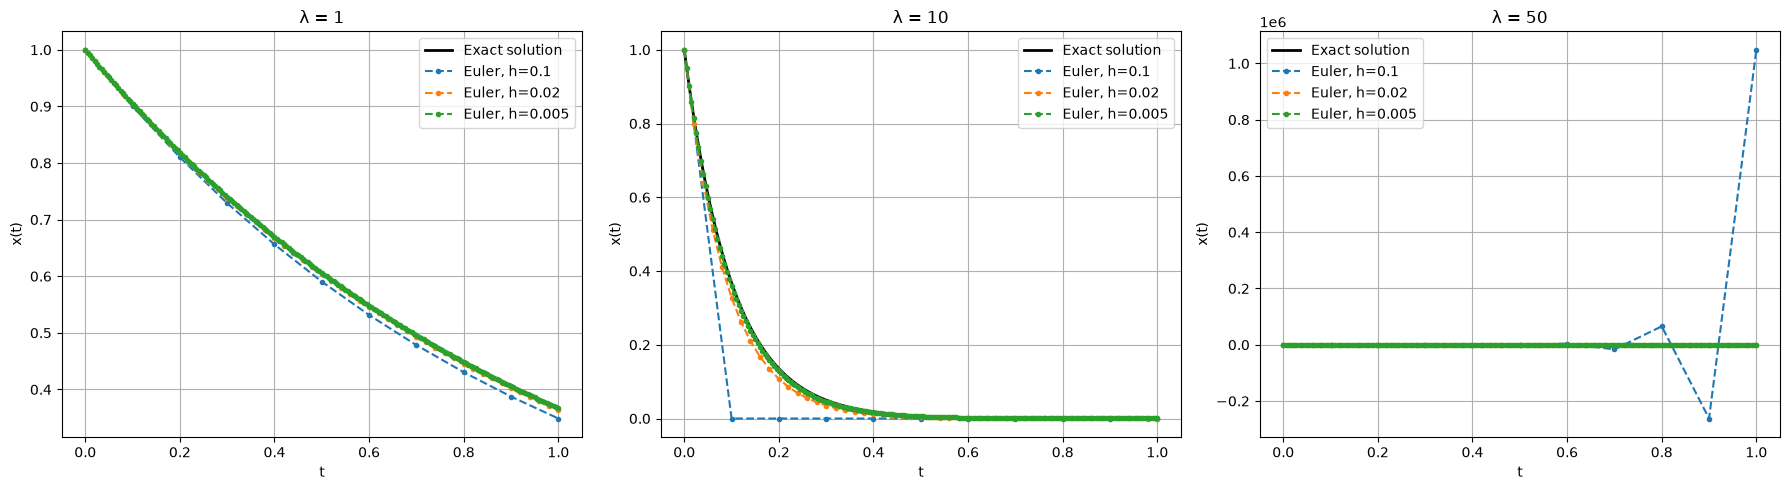

In [3]:
lambdas = [1, 10, 50]
step_sizes = [0.1, 0.02, 0.005]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, lam in zip(axes, lambdas):

    t_exact = np.linspace(0, 1, 1000)
    x_exact = np.exp(-lam * t_exact)

    ax.plot(t_exact, x_exact, 'k-', linewidth=2,
            label='Exact solution')

    for h in step_sizes:
        t, x = explicit_euler(lam, h)
        ax.plot(t, x, 'o--', markersize=3,
                label=f'Euler, h={h}')

    ax.set_title(f'λ = {lam}')
    ax.set_xlabel('t')
    ax.set_ylabel('x(t)')
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

The exact solution is

$$ x(t)=e^{-\lambda t}, $$

which decreases monotonically toward zero for every $$ \lambda>0. $$

The numerical solution depends on the amplification factor

$$ 1-\lambda h. $$

The Explicit Euler method is asymptotically stable when

$$ |1-\lambda h|<1, $$

which gives the stability condition

$$ \boxed{0<h<\frac{2}{\lambda}}. $$

The following observations can be made:

1. For small (lambda), the numerical solution approximates the exact solution well for sufficiently small step sizes.
2. Decreasing the step size generally improves the accuracy.
3. For large (lambda), a step size that works for smaller values of (lambda) may cause oscillations or instability.
4. When (lambda*h>2), the numerical solution grows in magnitude, even though the exact solution decays.
5. When (1< lambda*h <2), the numerical solution oscillates while its magnitude decreases.

<strong> Thus, Explicit Euler requires increasingly small step sizes as (lambda) becomes large. </strong>

<h2> Part b: </h2>

For this part, we consider

$$ \dot{x}(t)=-x(t),\qquad x(0)=1. $$

The exact solution is

$$ \boxed{x(t)=e^{-t}}. $$

We use the step sizes

$$ h_k=2^{-k},\qquad k=1,\ldots,10. $$

For each step size, we calculate the numerical solution using Explicit Euler and determine the global error at \(t=1\).

The global error is defined as

$$ \boxed{E(h)=|x(1)-x_N|}, $$

where \(x_N\) is the numerical approximation at the final time \(t_N=1\).

For Explicit Euler, the expected global error is

$$ E(h)\approx Ch, $$

where \(C\) is approximately constant for sufficiently small \(h\).

This indicates first-order convergence.

In [4]:
k_values = np.arange(1, 11)
h_values = 2.0 ** (-k_values)

errors = []

for h in h_values:

    t, x = explicit_euler(lam=1, h=h)

    x_exact_final = np.exp(-1)
    x_numerical_final = x[-1]

    error = abs(x_exact_final - x_numerical_final)

    errors.append(error)

errors = np.array(errors)

print("Step size h       Global error")
print("--------------------------------")

for h, error in zip(h_values, errors):
    print(f"{h:<18.8f}{error:.8e}")

Step size h       Global error
--------------------------------
0.50000000        1.17879441e-01
0.25000000        5.14731912e-02
0.12500000        2.42705254e-02
0.06250000        1.18053107e-02
0.03125000        5.82415192e-03
0.01562500        2.89291693e-03
0.00781250        1.44172525e-03
0.00390625        7.19686280e-04
0.00195312        3.59549917e-04
0.00097656        1.79701760e-04


If the global error satisfies

$$ E(h)\approx Ch^p, $$

then taking logarithms gives

$$ \log E(h)\approx\log C+p\log h. $$

Therefore, the slope of the error curve on a log–log plot estimates the convergence order \(p\).

For Explicit Euler, we expect the slope to be approximately \(1\).

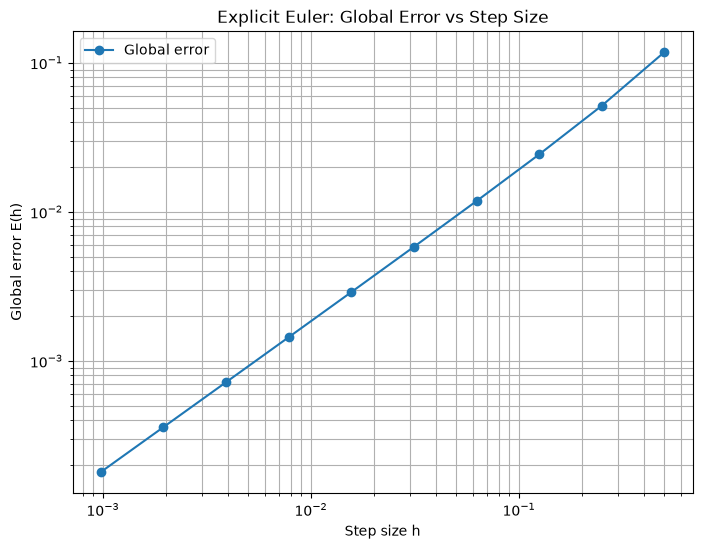

In [5]:
plt.figure(figsize=(8, 6))

plt.loglog(h_values, errors, 'o-', label='Global error')

plt.xlabel('Step size h')
plt.ylabel('Global error E(h)')
plt.title('Explicit Euler: Global Error vs Step Size')

plt.grid(True, which='both')
plt.legend()

plt.show()

In [6]:
log_h = np.log(h_values)
log_errors = np.log(errors)

slope, intercept = np.polyfit(log_h, log_errors, 1)

print(f"Estimated convergence order: {slope:.4f}")

Estimated convergence order: 1.0293


The log–log plot of the global error against the step size is approximately a straight line with slope \(1\).

The estimated convergence order is approximately

$$ \boxed{p\approx 1}. $$

<strong> This confirms that the Explicit Euler method has first-order global convergence. </strong>